# Card castle

Loads `outputs/card_castle/` and isolates each run's steady-state window.

A pair of runs, `no_gauss` and `gauss` (1500 N/m): a house of cards between the tip and the
button, one spring pulling toward the button, one pushing off the castle when the field is on.
Without the field the tip goes straight through; with it, the tip stalls where the two forces
balance. Scripted end to end (`castle_demo.py`), nothing dragged by hand. `TAU_LIMIT` is
0.35 N·m, same as `person_avoiding` and above button-pressing's 0.25.

Shows the tradeoff a person can't: without the field the body knocks the castle over. Same two
geometric numbers as `person_avoiding` — clearance of the whole backbone, and whether the tip
still reached the button.

Position and strength are read from the run itself, never the config.

**The arm leaves the y = 0 plane by up to 16 cm** (goal z re-tracks its own attachment point
each tick, gravity along -y). One run grazes the obstacle at 0.8 cm in x-z but is 12.2 cm away
in 3-D, so the geometry figure shows both projections plus the true 3-D distance, the one to
compare against sigma.

Older runs carry a smaller field set; the cells below adapt to what's present.


In [1]:
import sys, os, importlib.util
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../Kinematics'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_1P5, FIG_W_DOUBLE, set_font_size
from FK_Multi import FK_Multi
from VMC_utils.ConfigHelpers import strip_repeat
GRID = False
FONT_SIZE = 18
set_font_size(FONT_SIZE)

import glob
import numpy as np
import matplotlib.pyplot as plt

G_TO_N = 9.80665e-3   # load cell reports grams
S_BACKBONE = np.linspace(0.0, 1.0, 25)
SETTLE_S = 1.0        # [s] dropped from the front of a hold window, to let the arm arrive


def save_fig(fig, folder, name):
    """Every figure as PDF and SVG, next to the runs it came from."""
    for ext in ('pdf', 'svg'):
        fig.savefig(os.path.join('outputs', folder, f'{name}.{ext}'))

In [ ]:
def load_cfg(name):
    """Import a config variant by file name without copying it into place."""
    spec = importlib.util.spec_from_file_location('cfg_' + name, f'GUI_MultiVMC_Config_{name}.py')
    mod  = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


def list_runs(folder):
    """Every run recorded in outputs/<folder>/, by name.

    A run that didn't exit cleanly can leave `<run>.autosave.npz` (last 30 s
    checkpoint, readable) or `<run>.npz.part.npz` (truncated, skipped)."""
    names = []
    for path in sorted(glob.glob(os.path.join('outputs', folder, '*.npz'))):
        name = os.path.splitext(os.path.basename(path))[0]
        if name.endswith('.part'):
            print(f'[skip] {name}.npz -- interrupted write, not readable')
            continue
        if name.endswith('.autosave'):
            print(f'[note] {name}.npz is a checkpoint: the run did not exit cleanly, '
                  'so it ends at the last one taken')
        names.append(name)
    return names


def hold_window(d, tol=1e-9, settle=SETTLE_S, mark_index=0):
    """The measurement window.

    With an operator mark (Ctrl+C when the tip reached the button), the window
    starts there and runs until something moves again; `mark_index` picks which
    mark. Without one, falls back to the longest stretch where nothing moved
    (goal x/y, spring/damper params) -- can't tell "on the button" from "let go
    of the mouse", and can span a mid-run stiffness change.

    Goal z is excluded from the motion check: in `_person`/`_card_castle`
    (GOAL_Z_TRACK) it re-tracks the attachment point every tick and wiggles at
    ~1e-5 m from FK noise even when still, which fragmented the hold into single
    ticks. `_button`'s locked z is unaffected either way.

    Drops the first SETTLE_S so the arm's arrival isn't averaged in."""
    t   = d['t']
    sig = [d['goal'][:, :, :2].reshape(len(t), -1), d['k_params']]
    if 'c_params' in d:
        sig.append(d['c_params'])
    sig = np.hstack([np.asarray(s, dtype=float) for s in sig])

    changed = np.r_[True, np.abs(np.diff(sig, axis=0)).max(axis=1) > tol]
    seg     = np.cumsum(changed)

    marks = np.asarray(d.get('marks_t', []), dtype=float)
    marks = marks[np.isfinite(marks) & (marks >= t[0]) & (marks <= t[-1])]
    if len(marks) > mark_index:
        m0   = marks[mark_index]
        hold = (seg == seg[int(np.searchsorted(t, m0))]) & (t >= m0)
    else:
        hold = seg == np.bincount(seg).argmax()

    trimmed = hold & (t >= t[hold][0] + settle) if hold.any() else hold
    return trimmed if trimmed.any() else hold   # a mark right before Ctrl+C


def load_run(folder, name):
    """One run: hold window marked, newer log channels passed through when present."""
    raw = np.load(os.path.join('outputs', folder, name + '.npz'), allow_pickle=True)
    d   = {k: raw[k] for k in raw.files}   # forces the read now, not lazily

    hold     = hold_window(d)
    tip_goal = d['goal'][:, 0, :]
    k_gauss  = d['k_params'][:, 1]

    r = dict(name=name, folder=folder, raw=d, t=d['t'], hold=hold,
             goal=d['goal'], comp_pos=d['comp_pos'],
             q_motor=d['q_motor'], tau=d['tau'],
             k_params=d['k_params'], k_gauss=k_gauss,
             force_n=d['force'] * G_TO_N,
             s_params=d['comp_s_params'],
             comp_names=[str(n) for n in d['comp_names']],
             tau_limit=float(d['tau_limit'][0]),
             strength=float(k_gauss[hold].mean()),
             target=tip_goal[hold].mean(axis=0),
             obstacle=d['goal'][hold, 1, :].mean(axis=0))

    # ── Channels only newer runs carry ────────────────────────────────────────
    r['f_comp']    = d.get('f_comp')            # (n, N_VC, 3) [N] per element
    r['comp_vel']  = d.get('comp_vel')          # (n, N_VC, 3) [m/s]
    r['c_params']  = d.get('c_params')
    r['force_age'] = d.get('force_age')
    r['tau_raw']   = d.get('tau_raw', d['tau'])  # pre-limiter torque, else the clipped one
    r['clipped']   = np.any(np.abs(r['tau_raw']) > r['tau_limit'] + 1e-12, axis=1)
    r['has_pre']   = bool((d['t'] < 0).any())    # logged before the GUI connected
    r['force_live'] = bool(np.any(d['force'] != 0.0))
    # Group repeats by condition (button: `weak_r1..r5`); a person/card_castle
    # run is one file per level, so it's its own group.
    r['condition']   = strip_repeat(name)
    r['repeat']      = name[len(r['condition']):].lstrip('_') or None
    r['marks_t']     = np.asarray(d.get('marks_t', []), dtype=float)
    r['marks_label'] = [str(x) for x in d.get('marks_label', [])]
    return r


def backbone(run, hold=None):
    """FK backbone at the mean pose over a window (the hold window by default)."""
    mask = run['hold'] if hold is None else hold
    q_ss = run['q_motor'][mask].mean(axis=0)
    return np.array([FK_Multi(q_ss, s)[:3] for s in S_BACKBONE])


def load_all(folder):
    """Every readable run in a folder; one bad file doesn't stop the rest."""
    runs = []
    for name in list_runs(folder):
        try:
            runs.append(load_run(folder, name))
        except Exception as exc:
            print(f'[skip] {name}.npz -- {type(exc).__name__}: {exc}')
    # Sweep order, not alphabetical -- `medium_r1` would sort before `no_gauss_r1`
    # and reverse the legend. Runs at one strength (person/card_castle) just sort by name.
    return sorted(runs, key=lambda r: (r['strength'], r['name']))


def summary(runs):
    for r in runs:
        b   = backbone(r)
        clr = np.linalg.norm(b - r['obstacle'], axis=1).min()
        tip = r['comp_pos'][r['hold'], 0, :].mean(axis=0)
        r['clearance']   = float(clr)
        r['reach_error'] = float(np.linalg.norm(r['target'] - tip))
        t = r['t'][r['hold']]
        print(f"{r['name']:>14}  strength {r['strength']:6.0f}  "
              f"hold {t[0]:6.1f}-{t[-1]:6.1f}s ({r['hold'].sum():6d} samples)  "
              f"clearance {clr*100:5.1f} cm  reach err {r['reach_error']*100:5.1f} cm  "
              f"clip {100*r['clipped'][r['hold']].mean():4.0f}%  "
              f"force {'live' if r['force_live'] else 'FLAT'}  "
              f"window {'marked' if len(r['marks_t']) else 'inferred'}")

### The run itself

Everything the torque node logged, hold window shaded — used to judge a run (ramp, mid-run
slider moves, limiter, load cell) before taking any steady-state number from it. `t < 0`, when
present, is before the GUI connected.

In [ ]:
def plot_run(r, folder=None, zoom_pad=5.0):
    """Each run twice: whole run (left) and opening transient (right), since the
    ramp and goal placement are a single pixel wide on a 5-minute axis. Rows
    without a channel in this file are omitted."""
    t, hold = r['t'], r['hold']
    rows = ['pos', 'force_el', 'k', 'tau'] + (['load'] if r['force_live'] else [])
    # A diagnostic figure, not a paper one: five stacked rows do not fit the
    # paper font size, so it is shrunk here and nowhere else.
    with plt.rc_context({'axes.labelsize': 12, 'xtick.labelsize': 11,
                         'ytick.labelsize': 11, 'axes.titlesize': 12}):
        return _plot_run(r, rows, folder, zoom_pad)


def _plot_run(r, rows, folder, zoom_pad):
    t, hold = r['t'], r['hold']
    fig, axes = plt.subplots(len(rows), 2, sharex='col', sharey='row',
                             figsize=(FIG_W_DOUBLE, 0.95 * FIG_W_DOUBLE),
                             layout='constrained',
                             gridspec_kw=dict(width_ratios=[2.1, 1]))
    ax = {name: dict(full=axes[i, 0], zoom=axes[i, 1]) for i, name in enumerate(rows)}
    tau_max = np.abs(r['tau_raw']).max(axis=1)

    def draw(a, row, legend):
        if row == 'pos':
            # where the tip is, against where it was asked to be, per axis
            for j, lbl in enumerate('XYZ'):
                a.plot(t, r['comp_pos'][:, 0, j] * 100, color=COLORS[j], linewidth=1.4, label=lbl)
                a.plot(t, r['goal'][:, 0, j] * 100, '--', color=COLORS[j], linewidth=1.0, alpha=0.8)
            if legend:
                a.set_ylabel('Tip [cm]')
                a.legend(ncol=3, fontsize=10, loc='lower right',
                         title='solid: tip,  dashed: goal', title_fontsize=9)
        elif row == 'force_el':
            # what each element is actually pulling with
            if r['f_comp'] is not None:
                for i, nm in enumerate(r['comp_names']):
                    a.plot(t, np.linalg.norm(r['f_comp'][:, i], axis=1), color=COLORS[i],
                           linewidth=1.4, label=nm)
            else:
                a.plot(t, np.linalg.norm(r['raw']['f_virtual'], axis=1), color=COLORS[9],
                       linewidth=1.4, label='sum over elements')
            if legend:
                a.set_ylabel('|F| [N]' if r['f_comp'] is not None else '|sum F| [N]')
                a.legend(ncol=3, fontsize=10, loc='lower right')
                if r['f_comp'] is None:
                    a.text(0.01, 0.95, 'per-element forces not logged in this run',
                           transform=a.transAxes, fontsize=9, va='top', color=COLORS[1])
        elif row == 'k':
            # the parameters, which is where the ramp and any slider move show up
            for i, nm in enumerate(r['comp_names']):
                a.plot(t, r['k_params'][:, i], color=COLORS[i], linewidth=1.4,
                       linestyle=['-', '--', ':'][i % 3], label=nm)
            a.set_yscale('symlog', linthresh=1.0)
            if legend:
                a.set_ylabel('Spring param')
                a.legend(ncol=3, fontsize=10, loc='lower right')
        elif row == 'tau':
            # how close the limiter came, and where it bit
            a.plot(t, tau_max, color=COLORS[3], linewidth=1.4, label='max |tau| asked')
            a.axhline(r['tau_limit'], color='k', linewidth=0.9, alpha=0.6)
            if r['clipped'].any():
                a.fill_between(t, 0, tau_max, where=r['clipped'], color=COLORS[7], alpha=0.25,
                               linewidth=0, label=f"clipped ({100*r['clipped'].mean():.0f}% of run)")
            a.set_ylim(0, r['tau_limit'] * 1.15)
            if legend:
                a.set_ylabel('Torque [N m]')
                a.legend(fontsize=10, loc='lower right')
        elif row == 'load':
            a.plot(t, r['force_n'], color=COLORS[4], linewidth=1.4)
            if r['force_age'] is not None:
                stale = np.nan_to_num(r['force_age'], nan=1e3) > 1.0
                if stale.any():
                    a.fill_between(t, r['force_n'].min(), r['force_n'].max(), where=stale,
                                   color=COLORS[9], alpha=0.25, linewidth=0,
                                   label='reading > 1 s old')
                    if legend:
                        a.legend(fontsize=10, loc='lower right')
            if legend:
                a.set_ylabel('Shear [N]')

    for name in rows:
        for which, a in ax[name].items():
            draw(a, name, legend=(which == 'full'))
            a.axvspan(t[hold][0], t[hold][-1], color=COLORS[2], alpha=0.08, linewidth=0, zorder=0)
            if r['has_pre']:
                a.axvline(0.0, color='k', linewidth=0.8, alpha=0.4)   # GUI connected here
            for mt, lbl in zip(r['marks_t'], r['marks_label']):
                a.axvline(mt, color=COLORS[7], linewidth=1.1, alpha=0.9, linestyle=':')
                if name == rows[0]:
                    a.text(mt, 1.01, f' {lbl}', transform=a.get_xaxis_transform(),
                           rotation=90, va='bottom', ha='left', fontsize=8, color=COLORS[7])
            a.grid(GRID)

    ax[rows[0]]['zoom'].set_xlim(t[0], t[hold][0] + zoom_pad)
    ax[rows[0]]['zoom'].set_title(f'first {t[hold][0] + zoom_pad - t[0]:.0f} s', fontsize=11)
    ax[rows[0]]['full'].set_title('whole run', fontsize=11)
    for a in axes[-1]:
        a.set_xlabel('Time [s]')
    fig.suptitle(f"{r['name']}  --  Gaussian strength {r['strength']:.0f} N/m")
    if folder:
        save_fig(fig, folder, f"run_{r['name']}")
    plt.show()



      no_gauss  strength      0  hold   29.1-  38.1s (  2972 samples)  clearance   2.7 cm  reach err  19.5 cm  clip    0%  force FLAT  window marked
         gauss  strength   1500  hold   29.1-  38.1s (  2975 samples)  clearance   9.9 cm  reach err  22.0 cm  clip    0%  force FLAT  window marked


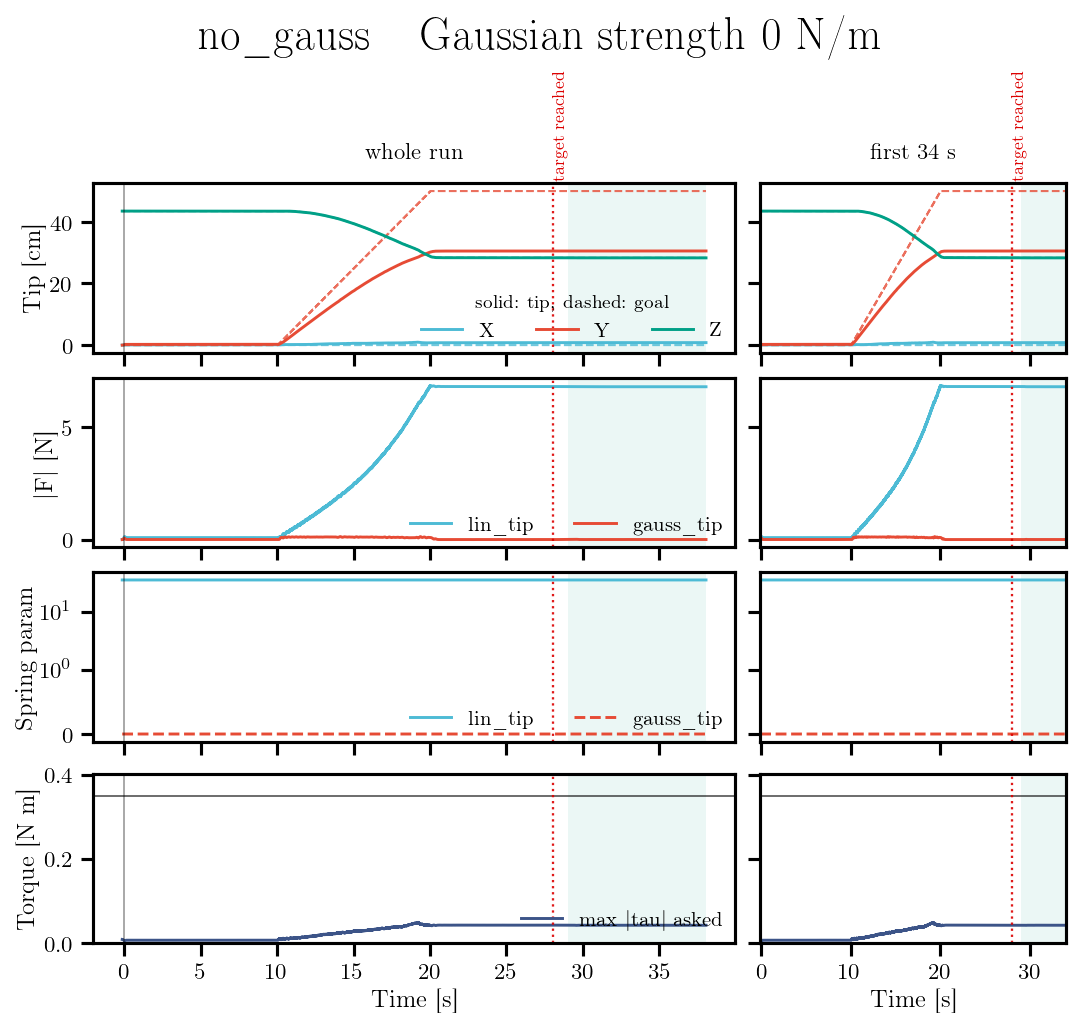

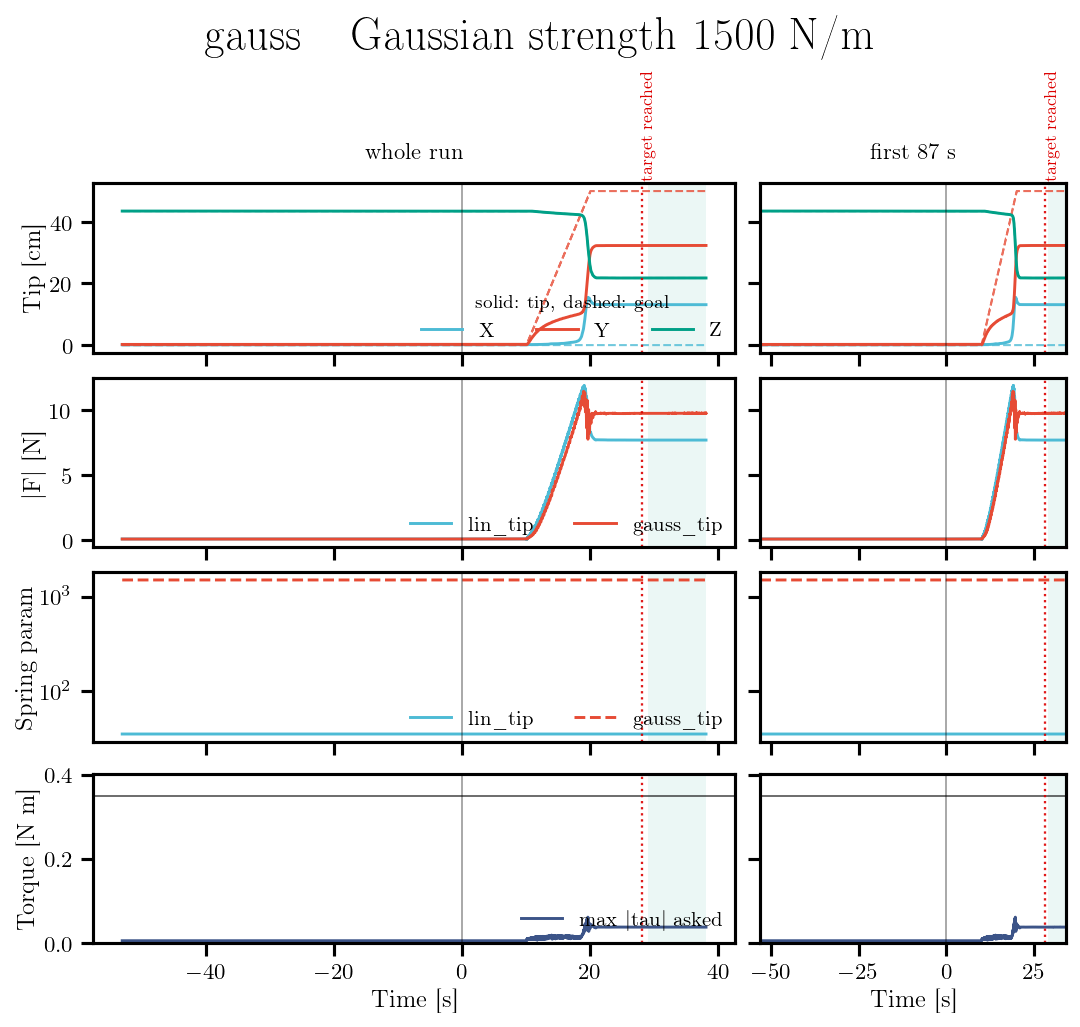

In [4]:
cfg_c  = load_cfg('card_castle')
runs_c = load_all('card_castle')
if not runs_c:
    print('outputs/card_castle/ is empty -- record the two cases first '
          '(README: --run gauss first, then rebuild and --run no_gauss).')
else:
    summary(runs_c)
    missing = [c for c in cfg_c.GAUSS_CONDITIONS if c not in {r['name'] for r in runs_c}]
    if missing:
        print('\n[note] not recorded yet: ' + ', '.join(missing))
    for r in runs_c:
        plot_run(r, folder='card_castle')


### Geometry

Three views of the same pose. The two projections show sigma as a circle — a backbone inside
it can still be far from the obstacle in 3-D. The right panel is the true 3-D distance along
the backbone, the one to compare against sigma.

In [5]:
def plot_geometry(runs, cfg, folder, obstacle_label='obstacle', name='backbone'):
    fig, (ax_xz, ax_xy, ax_d) = plt.subplots(
        1, 3, figsize=(FIG_W_DOUBLE, 0.52 * FIG_W_DOUBLE), layout='constrained',
        gridspec_kw=dict(width_ratios=[1, 1, 1.15]))

    obs = runs[0]['obstacle']
    tgt = runs[0]['target']
    conds = sorted({r['condition'] for r in runs},
                   key=lambda c: next(x['strength'] for x in runs if x['condition'] == c))
    seen  = set()
    for r in runs:
        i   = conds.index(r['condition'])          # colour by condition, not by file
        b   = backbone(r)
        lbl = None if r['condition'] in seen else f"{r['condition']} ({r['strength']:.0f})"
        seen.add(r['condition'])
        ax_xz.plot(b[:, 0] * 100, b[:, 2] * 100, color=COLORS[i], linewidth=2.0,
                   alpha=0.85, zorder=3, label=lbl)
        ax_xy.plot(b[:, 0] * 100, b[:, 1] * 100, color=COLORS[i], linewidth=2.0, zorder=3)
        ax_d.plot(S_BACKBONE, np.linalg.norm(b - r['obstacle'], axis=1) * 100,
                  color=COLORS[i], linewidth=2.0, label=lbl)
        for s in r['s_params'][1:]:            # the Gaussian attachment points
            p = b[np.argmin(np.abs(S_BACKBONE - s))]
            ax_xz.plot(p[0] * 100, p[2] * 100, 'o', color=COLORS[i], markersize=4, zorder=4)
            ax_xy.plot(p[0] * 100, p[1] * 100, 'o', color=COLORS[i], markersize=4, zorder=4)

    for a, (u, v), (ul, vl) in ((ax_xz, (0, 2), ('X [cm]', 'Z [cm]')),
                                (ax_xy, (0, 1), ('X [cm]', 'Y [cm]'))):
        a.plot(tgt[u] * 100, tgt[v] * 100, '*', color='k', markersize=13, zorder=5, label='button')
        a.plot(obs[u] * 100, obs[v] * 100, 'X', color='k', markersize=9, zorder=5, label=obstacle_label)
        # The true silhouette of a sphere of radius sigma -- and the trap: a
        # backbone drawn inside it is not necessarily within sigma in 3-D.
        a.add_patch(plt.Circle((obs[u] * 100, obs[v] * 100), cfg.SIGMA * 100, fill=False,
                               linestyle='--', color='k', linewidth=0.9, alpha=0.5, zorder=2))
        a.set_xlabel(ul); a.set_ylabel(vl)
        a.set_aspect('equal'); a.grid(GRID)

    ax_xz.set_title('side', fontsize=12)
    ax_xy.set_title('top', fontsize=12)
    h, l = ax_xz.get_legend_handles_labels()
    ax_xz.legend(h[-2:], l[-2:], fontsize=10, loc='lower left', framealpha=0.9)

    # Same horizontal scale in both projections, so the two views can be read
    # against each other rather than as two unrelated pictures.
    xlim = (min(ax_xz.get_xlim()[0], ax_xy.get_xlim()[0]),
            max(ax_xz.get_xlim()[1], ax_xy.get_xlim()[1]))
    ax_xz.set_xlim(*xlim)
    ax_xy.set_xlim(*xlim)

    ax_d.axhline(cfg.SIGMA * 100, color='k', linewidth=0.9, alpha=0.5)
    ax_d.text(0.02, cfg.SIGMA * 100, ' sigma', va='bottom', fontsize=10, color='k', alpha=0.7)
    ax_d.set_title('3-D, no projection', fontsize=12)
    ax_d.set_xlabel('s along backbone')
    ax_d.set_ylabel('Distance [cm]')
    ax_d.set_ylim(0, None)
    ax_d.grid(GRID)
    ax_d.legend(fontsize=10, loc='lower right')

    save_fig(fig, folder, name)
    plt.show()




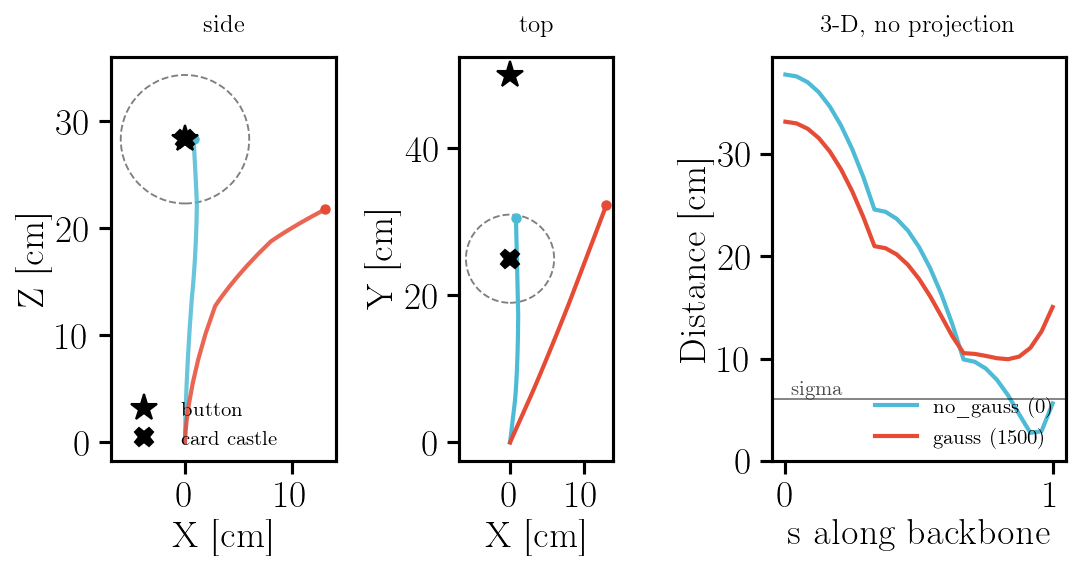

In [6]:
if runs_c:
    plot_geometry(runs_c, cfg_c, 'card_castle', obstacle_label='card castle')


In [ ]:
def plot_tradeoff(runs, cfg, folder, obstacle_label='obstacle'):
    """Clearance bought, reach given up, across strength levels (from k_params
    over each run's own window, not the nominal config value)."""
    if len(runs) < 2:
        print(f'{folder}: {len(runs)} run(s) recorded -- need at least two levels to compare.')
        return
    s   = np.array([r['strength'] for r in runs])
    o   = np.argsort(s)
    clr = np.array([r['clearance'] * 100 for r in runs])[o]
    err = np.array([r['reach_error'] * 100 for r in runs])[o]

    fig, ax = plt.subplots(figsize=(FIG_W_1P5, FIG_W_SINGLE * 0.85))
    ax.plot(s[o], clr, marker='o', color=COLORS[2], linewidth=1.8, markersize=6,
            label=f'clearance to {obstacle_label}')
    ax.axhline(cfg.SIGMA * 100, color='k', linewidth=0.8, alpha=0.4)
    ax.set_xlabel('Gaussian strength [N/m]')
    ax.set_ylabel('Clearance [cm]')
    ax.set_xlim(0, None)
    ax.set_ylim(0, None)
    ax.grid(GRID)
    for x, y, r in zip(s[o], clr, [runs[i] for i in o]):
        ax.annotate(r['name'], (x, y), textcoords='offset points', xytext=(0, 8),
                    ha='center', fontsize=10)

    ax2 = ax.twinx()
    ax2.plot(s[o], err, marker='s', color=COLORS[1], linewidth=1.8, markersize=6,
             linestyle='--', label='reach error')
    ax2.set_ylabel('Reach error [cm]')
    ax2.set_ylim(0, None)

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=10, loc='center right')
    fig.tight_layout()
    save_fig(fig, folder, 'tradeoff')
    plt.show()


if runs_c:
    plot_tradeoff(runs_c, cfg_c, 'card_castle', obstacle_label='card castle')


In [8]:
# Clearance bought and reach given up.
if len(runs_c) < 2:
    print(f'{len(runs_c)} run(s) -- need both cases to compare.')
else:
    s_r = np.array([r['strength'] for r in runs_c]); o = np.argsort(s_r)
    clr = np.array([r['clearance'] * 100 for r in runs_c])[o]
    err = np.array([r['reach_error'] * 100 for r in runs_c])[o]
    for i, j in enumerate(o):
        print(f"  {runs_c[j]['name']:>9}  k={s_r[j]:>6.0f}  clearance {clr[i]:5.1f} cm  "
              f"reach err {err[i]:5.1f} cm")
    print(f'  -> clearance {clr[-1] - clr[0]:+.1f} cm, reach error {err[-1] - err[0]:+.1f} cm')

   no_gauss  k=     0  clearance   2.7 cm  reach err  19.5 cm
      gauss  k=  1500  clearance   9.9 cm  reach err  22.0 cm
  -> clearance +7.2 cm, reach error +2.5 cm
